#  Analyse de la cible (Target Analysis)

##  Contexte et objectifs

Cette étape consiste à analyser la variable cible `target_event`, construite à partir des quatre périodes de fuite d'air documentées dans le dataset MetroPT-3.

L'objectif est de comprendre :

- La répartition des classes positives et négatives.
- Le niveau de déséquilibre de la cible.
- La contribution de chaque événement à la classe positive.
- La distribution temporelle des événements.
- Les conséquences de ces caractéristiques sur la future modélisation.

Cette analyse permettra de mieux définir les stratégies d'entraînement, de validation et d'évaluation des modèles de classification.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import yaml

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

In [2]:
with open("../config.yaml", "r", encoding="utf-8") as fichier:
    config = yaml.safe_load(fichier)

chemin_dataset = (
    Path("../")
    / config["data"]["processed_path"]
    / config["data"]["processed_dataset_name"]
)

df = pd.read_csv(chemin_dataset)

df["timestamp"] = pd.to_datetime(df["timestamp"])
df["event_id"] = df["event_id"].astype("Int64")

print("Dataset chargé :", df.shape)

Dataset chargé : (1516948, 19)


In [7]:
# Récupération du dossier de sauvegarde des figures
DOSSIER_FIGURES = Path("../") / config["artefacts"]["figures_dir"]

# Création du dossier s'il n'existe pas
DOSSIER_FIGURES.mkdir(parents=True, exist_ok=True)

print("Dossier des figures :", DOSSIER_FIGURES.resolve())

Dossier des figures : C:\Users\ngueb\Desktop\Prédictive_maintenance_MLOPS\reports\figures


In [3]:
assert "target_event" in df.columns
assert "event_id" in df.columns
assert df["target_event"].isin([0, 1]).all()

print("Nombre de valeurs manquantes dans target_event :",
      df["target_event"].isna().sum())

print("Nombre de valeurs manquantes dans event_id :",
      df["event_id"].isna().sum())

print("Chargement et contrôles terminés.")

Nombre de valeurs manquantes dans target_event : 0
Nombre de valeurs manquantes dans event_id : 1486994
Chargement et contrôles terminés.


##  Distribution globale de la cible

Cette section étudie la répartition des deux classes de la variable `target_event`.

L'objectif est de quantifier le déséquilibre entre les observations associées aux événements de fuite d'air documentés et les observations situées en dehors de ces périodes.

In [4]:
# Calcul des effectifs
distribution_cible = df["target_event"].value_counts().sort_index()

# Calcul des proportions
pourcentage_cible = (
    df["target_event"].value_counts(normalize=True).sort_index() * 100
)

# Tableau récapitulatif
resume_cible = pd.DataFrame({
    "Effectif": distribution_cible,
    "Pourcentage (%)": pourcentage_cible
})

resume_cible.index = ["Classe 0 - Négative", "Classe 1 - Positive"]

display(resume_cible)

,Effectif,Pourcentage (%)
Classe 0 - Négative,1486994,98.0254
Classe 1 - Positive,29954,1.9746


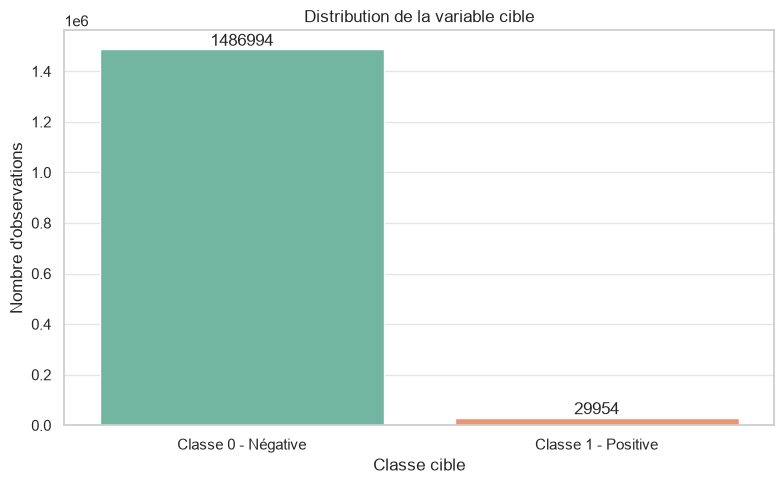

Figure enregistrée : ..\reports\figures\03_target_distribution.png


In [8]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="target_event",
    hue="target_event",
    palette="Set2",
    legend=False
)

ax.set_title("Distribution de la variable cible")
ax.set_xlabel("Classe cible")
ax.set_ylabel("Nombre d'observations")
ax.set_xticks([0, 1])
ax.set_xticklabels(["Classe 0 - Négative", "Classe 1 - Positive"])

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.tight_layout()

# Sauvegarde de la figure
chemin_figure = DOSSIER_FIGURES / "03_target_distribution.png"

plt.savefig(
    chemin_figure,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Figure enregistrée :", chemin_figure)

In [9]:
nb_negatifs = (df["target_event"] == 0).sum()
nb_positifs = (df["target_event"] == 1).sum()

ratio_classes = nb_negatifs / nb_positifs

print(f"Observations négatives : {nb_negatifs:,}")
print(f"Observations positives : {nb_positifs:,}")
print(f"Ratio négatif / positif : {ratio_classes:.2f}")

Observations négatives : 1,486,994
Observations positives : 29,954
Ratio négatif / positif : 49.64


### Interprétation

La variable cible présente un fort déséquilibre de classes. Les observations négatives représentent 98,03 % du dataset, contre seulement 1,97 % pour les observations positives.

Le ratio négatif/positif est de 49,64, ce qui signifie que le dataset contient environ 50 observations négatives pour une observation positive.

Cette situation rend l'accuracy insuffisante comme métrique principale. Un modèle pourrait obtenir une accuracy élevée en prédisant majoritairement la classe négative, sans détecter correctement les événements de fuite documentés.

L'évaluation devra donc accorder une attention particulière au Recall, à la Precision, au F1-score, au F2-score et à l'Average Precision.

In [10]:
# Répartition des observations positives par événement
distribution_evenements = (
    df[df["target_event"] == 1]
    .groupby("event_id")
    .size()
    .rename("Effectif")
    .to_frame()
)

distribution_evenements["Pourcentage (%)"] = (
    distribution_evenements["Effectif"]
    / distribution_evenements["Effectif"].sum()
    * 100
)

display(distribution_evenements)

,Effectif,Pourcentage (%)
event_id,,
1,8657,28.9010
2,2360,7.8787
3,17315,57.8053
4,1622,5.4150


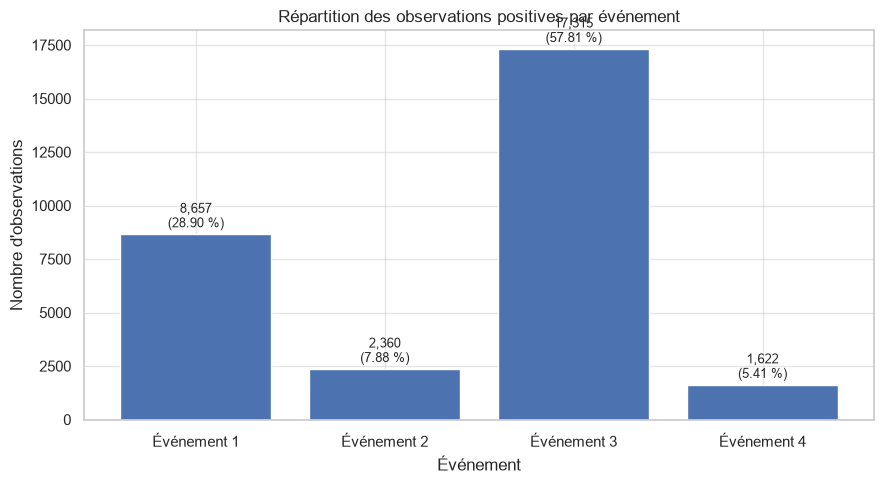

Figure enregistrée : ..\reports\figures\03_target_by_event.png


In [11]:
# Préparation des données
distribution_evenements = (
    df[df["target_event"] == 1]
    .groupby("event_id")
    .size()
)

effectifs = distribution_evenements.values
labels = [f"Événement {i}" for i in distribution_evenements.index]
pourcentages = effectifs / effectifs.sum() * 100

# Création de la figure
fig, ax = plt.subplots(figsize=(9, 5))

barres = ax.bar(labels, effectifs)

ax.set_title("Répartition des observations positives par événement")
ax.set_xlabel("Événement")
ax.set_ylabel("Nombre d'observations")

# Affichage des effectifs et pourcentages
for barre, effectif, pourcentage in zip(
    barres, effectifs, pourcentages
):
    ax.annotate(
        f"{effectif:,}\n({pourcentage:.2f} %)",
        xy=(barre.get_x() + barre.get_width() / 2, barre.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

plt.tight_layout()

# Enregistrement
chemin_figure = DOSSIER_FIGURES / "03_target_by_event.png"
plt.savefig(chemin_figure, dpi=300, bbox_inches="tight")

plt.show()
plt.close()

print("Figure enregistrée :", chemin_figure)

### Interprétation de la répartition par événement

La répartition des observations positives montre une contribution inégale des quatre événements documentés.

L'événement 3 représente 57,81 % des observations positives, suivi de l'événement 1 avec 28,91 %. Les événements 2 et 4 représentent respectivement 7,88 % et 5,42 %.

Cette répartition met en évidence une hétérogénéité importante entre les événements. Elle devra être prise en compte lors de la validation des modèles afin d'évaluer leur capacité à généraliser à des événements non utilisés pendant l'entraînement.

Il sera notamment important de ne pas limiter l'évaluation à une performance globale, mais d'examiner également les résultats événement par événement.

## Analyse temporelle des événements

Cette section étudie la répartition temporelle des observations positives à partir de la variable `timestamp`.

L'objectif est de visualiser les périodes associées aux quatre événements documentés et d'observer leur répartition dans l'historique du dataset.

In [12]:
# Extraction des observations positives
df_positifs = df.loc[
    df["target_event"] == 1,
    ["timestamp", "event_id", "target_event"]
].copy()

# Vérification de la période couverte
print("Première observation positive :", df_positifs["timestamp"].min())
print("Dernière observation positive :", df_positifs["timestamp"].max())

print("\nNombre d'observations positives :", len(df_positifs))
print("\nNombre d'événements :", df_positifs["event_id"].nunique())

Première observation positive : 2020-04-18 00:00:01
Dernière observation positive : 2020-07-15 19:00:00

Nombre d'observations positives : 29954

Nombre d'événements : 4


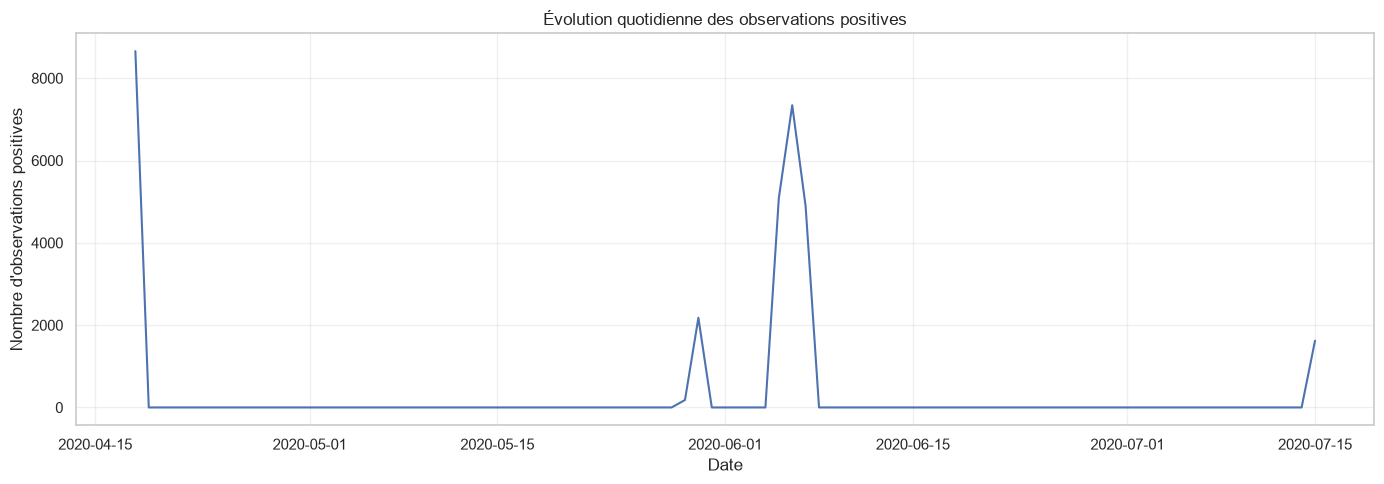

Figure enregistrée : ..\reports\figures\03_target_temporal_distribution.png


In [13]:
# Comptage quotidien des observations positives
positifs_par_jour = (
    df_positifs
    .set_index("timestamp")
    .resample("D")
    .size()
)

# Visualisation
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    positifs_par_jour.index,
    positifs_par_jour.values,
    linewidth=1.5
)

ax.set_title("Évolution quotidienne des observations positives")
ax.set_xlabel("Date")
ax.set_ylabel("Nombre d'observations positives")
ax.grid(True, alpha=0.3)

plt.tight_layout()

# Sauvegarde
chemin_figure = DOSSIER_FIGURES / "03_target_temporal_distribution.png"

plt.savefig(
    chemin_figure,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Figure enregistrée :", chemin_figure)

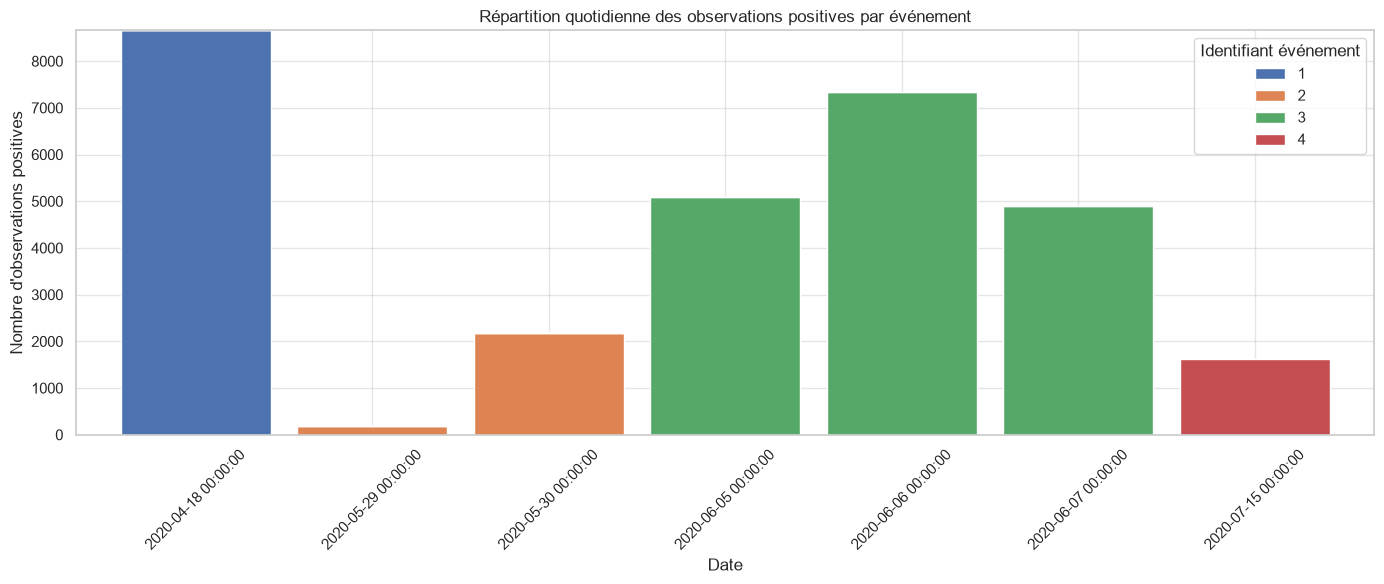

Figure enregistrée : ..\reports\figures\03_target_daily_by_event.png


In [16]:
# Comptage quotidien par événement
positifs_par_jour_evenement = (
    df_positifs
    .groupby([
        pd.Grouper(key="timestamp", freq="D"),
        "event_id"
    ])
    .size()
    .unstack(fill_value=0)
)

# Visualisation
fig, ax = plt.subplots(figsize=(14, 6))

positifs_par_jour_evenement.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    width=0.85
)

ax.set_title("Répartition quotidienne des observations positives par événement")
ax.set_xlabel("Date")
ax.set_ylabel("Nombre d'observations positives")
ax.legend(title="Identifiant événement")

# Réduction du nombre de dates affichées sur l'axe X
ax.tick_params(axis="x", labelrotation=45)
plt.tight_layout()

plt.xticks(rotation=45)
plt.tight_layout()

# Sauvegarde
chemin_figure = DOSSIER_FIGURES / "03_target_daily_by_event.png"

plt.savefig(
    chemin_figure,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Figure enregistrée :", chemin_figure)

In [15]:
resume_temporel = (
    df_positifs
    .groupby("event_id")
    .agg(
        premiere_observation=("timestamp", "min"),
        derniere_observation=("timestamp", "max"),
        nombre_observations=("timestamp", "size"),
        nombre_jours_actifs=(
            "timestamp",
            lambda x: x.dt.normalize().nunique()
        )
    )
)

display(resume_temporel)

,premiere_observation,derniere_observation,nombre_observations,nombre_jours_actifs
event_id,,,,
1,2020-04-18 00:00:01,2020-04-18 23:58:56,8657,1
2,2020-05-29 23:30:08,2020-05-30 05:59:54,2360,2
3,2020-06-05 10:00:04,2020-06-07 14:19:39,17315,3
4,2020-07-15 14:30:00,2020-07-15 19:00:00,1622,1


### Interprétation de l'analyse temporelle

L'analyse temporelle montre que les observations positives sont concentrées sur quatre périodes distinctes, correspondant aux quatre événements de fuite d'air documentés.

Les événements 1 et 4 présentent chacun une journée active. L'événement 2 s'étend sur deux journées, tandis que l'événement 3 s'étend sur trois journées.

Les dates des premières et dernières observations positives sont cohérentes avec les intervalles définis dans la configuration du projet.

Cette analyse confirme la concentration temporelle de la classe positive. Elle souligne également l'importance de respecter la chronologie des observations lors de la validation des modèles afin d'éviter toute fuite d'information temporelle.

In [17]:
# Calcul des caractéristiques temporelles par événement
resume_durees = (
    df_positifs
    .groupby("event_id")
    .agg(
        premiere_observation=("timestamp", "min"),
        derniere_observation=("timestamp", "max"),
        nombre_observations=("timestamp", "size"),
        nombre_jours_actifs=(
            "timestamp",
            lambda x: x.dt.normalize().nunique()
        )
    )
)

# Durée entre première et dernière observation
resume_durees["duree_observee"] = (
    resume_durees["derniere_observation"]
    - resume_durees["premiere_observation"]
)

display(resume_durees)

,premiere_observation,derniere_observation,nombre_observations,nombre_jours_actifs,duree_observee
event_id,,,,,
1,2020-04-18 00:00:01,2020-04-18 23:58:56,8657,1,0 days 23:58:55
2,2020-05-29 23:30:08,2020-05-30 05:59:54,2360,2,0 days 06:29:46
3,2020-06-05 10:00:04,2020-06-07 14:19:39,17315,3,2 days 04:19:35
4,2020-07-15 14:30:00,2020-07-15 19:00:00,1622,1,0 days 04:30:00


In [19]:
# Récupération des événements depuis la configuration
evenements_config = config["target"]["events"]

# Construction du tableau des durées théoriques
durees_theoriques = []

for evenement in evenements_config:
    debut = pd.to_datetime(evenement["start"])
    fin = pd.to_datetime(evenement["end"])

    durees_theoriques.append({
        "event_id": evenement["event_id"],
        "debut_theorique": debut,
        "fin_theorique": fin,
        "duree_theorique": fin - debut
    })

df_durees_theoriques = pd.DataFrame(durees_theoriques).set_index("event_id")

display(df_durees_theoriques)

,debut_theorique,fin_theorique,duree_theorique
event_id,,,
1,2020-04-18 00:00:00,2020-04-18 23:59:00,0 days 23:59:00
2,2020-05-29 23:30:00,2020-05-30 06:00:00,0 days 06:30:00
3,2020-06-05 10:00:00,2020-06-07 14:30:00,2 days 04:30:00
4,2020-07-15 14:30:00,2020-07-15 19:00:00,0 days 04:30:00


In [21]:
# Comparaison entre durées observées et théoriques
comparaison_durees = df_durees_theoriques.join(
    resume_durees[["duree_observee", "nombre_observations"]]
)

comparaison_durees["ecart_duree"] = (
    comparaison_durees["duree_theorique"]
    - comparaison_durees["duree_observee"]
)

display(comparaison_durees)

,debut_theorique,fin_theorique,duree_theorique,duree_observee,nombre_observations,ecart_duree
event_id,,,,,,
1,2020-04-18 00:00:00,2020-04-18 23:59:00,0 days 23:59:00,0 days 23:58:55,8657,0 days 00:00:05
2,2020-05-29 23:30:00,2020-05-30 06:00:00,0 days 06:30:00,0 days 06:29:46,2360,0 days 00:00:14
3,2020-06-05 10:00:00,2020-06-07 14:30:00,2 days 04:30:00,2 days 04:19:35,17315,0 days 00:10:25
4,2020-07-15 14:30:00,2020-07-15 19:00:00,0 days 04:30:00,0 days 04:30:00,1622,0 days 00:00:00


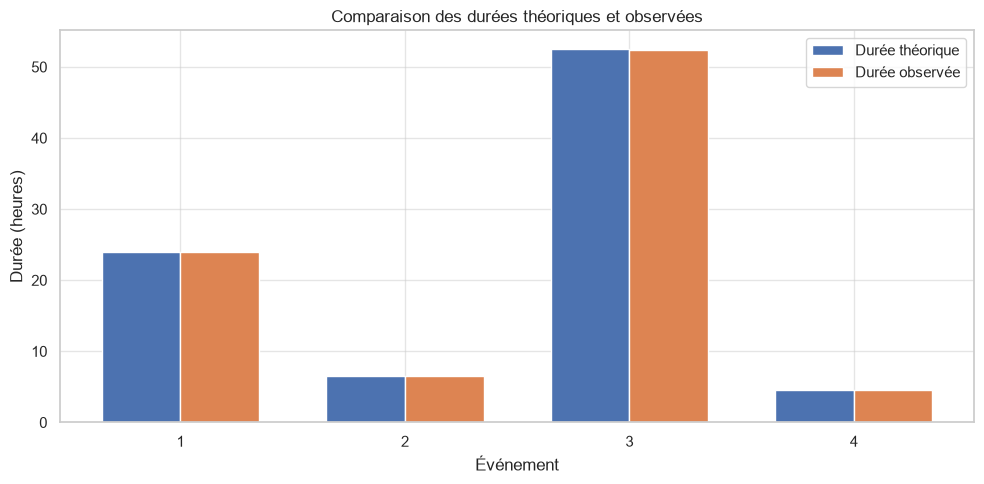

Figure enregistrée : ..\reports\figures\03_event_durations.png


In [22]:
# Conversion des durées en heures
comparaison_heures = comparaison_durees.copy()

comparaison_heures["duree_theorique_h"] = (
    comparaison_heures["duree_theorique"].dt.total_seconds() / 3600
)

comparaison_heures["duree_observee_h"] = (
    comparaison_heures["duree_observee"].dt.total_seconds() / 3600
)

# Préparation du graphique
fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(comparaison_heures))
largeur = 0.35

ax.bar(
    x - largeur / 2,
    comparaison_heures["duree_theorique_h"],
    largeur,
    label="Durée théorique"
)

ax.bar(
    x + largeur / 2,
    comparaison_heures["duree_observee_h"],
    largeur,
    label="Durée observée"
)

ax.set_title("Comparaison des durées théoriques et observées")
ax.set_xlabel("Événement")
ax.set_ylabel("Durée (heures)")
ax.set_xticks(x)
ax.set_xticklabels(comparaison_heures.index)
ax.legend()

plt.tight_layout()

# Sauvegarde
chemin_figure = DOSSIER_FIGURES / "03_event_durations.png"

plt.savefig(
    chemin_figure,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Figure enregistrée :", chemin_figure)

### Interprétation des durées des événements

La comparaison entre les durées théoriques et les durées observées montre une bonne cohérence entre les intervalles documentés et les timestamps présents dans le dataset.

Les écarts mesurés sont de 5 secondes pour l'événement 1, 14 secondes pour l'événement 2, 10 minutes et 25 secondes pour l'événement 3 et 0 seconde pour l'événement 4.

L'événement 3 présente l'écart le plus important. Cette différence est conservée comme élément de traçabilité et ne constitue pas, à elle seule, une preuve d'anomalie dans les données.

Les durées observées permettent également de constater que les événements ont des temporalités différentes, allant de 4 heures et 30 minutes à plus de 52 heures.

Ces différences devront être prises en compte dans les analyses temporelles et dans la stratégie de validation des futurs modèles.

## Synthèse des observations

L'analyse de la variable cible `target_event` a permis de mettre en évidence plusieurs caractéristiques importantes du dataset MetroPT-3.

### Déséquilibre des classes

Le dataset contient 1 486 994 observations négatives (98,03 %) et 29 954 observations positives (1,97 %).

Le ratio négatif/positif est de 49,64. Ce déséquilibre constitue une contrainte importante pour l'apprentissage et l'évaluation des modèles.

###  Répartition des événements

Les observations positives sont réparties de manière inégale entre les quatre événements :

- Événement 1 : 8 657 observations (28,91 %).
- Événement 2 : 2 360 observations (7,88 %).
- Événement 3 : 17 315 observations (57,81 %).
- Événement 4 : 1 622 observations (5,42 %).

L'événement 3 représente la majorité des observations positives.

###  Répartition temporelle

Les observations positives sont concentrées sur quatre périodes distinctes, correspondant aux intervalles documentés dans la configuration du projet.

Les événements présentent des durées et des répartitions temporelles différentes.

###  Cohérence des durées

La comparaison des durées théoriques et observées montre une bonne cohérence entre les intervalles configurés et les timestamps présents dans le dataset.

L'écart le plus important concerne l'événement 3, avec 10 minutes et 25 secondes.

### Conséquences pour la modélisation

Ces observations orientent les choix méthodologiques pour la suite du projet :

- Prendre en compte le déséquilibre des classes.
- Ne pas utiliser l'accuracy comme seule métrique d'évaluation.
- Examiner les performances sur chaque événement.
- Respecter la chronologie des données lors de la validation.
- Évaluer la capacité du modèle à généraliser à un événement non utilisé pendant son entraînement.

##  Conclusion

L'analyse de la cible a permis de vérifier la structure, la distribution et la cohérence temporelle de la variable `target_event`.

Les quatre événements documentés représentent 29 954 observations positives sur un total de 1 516 948 observations. La distribution est fortement déséquilibrée, avec une classe positive représentant seulement 1,97 % du dataset.

Les événements présentent également des contributions et des durées différentes. Cette hétérogénéité devra être prise en compte lors de la construction et de l'évaluation des modèles.

La cible est exploitable pour poursuivre le projet de classification, dans le périmètre précis des quatre événements de fuite d'air documentés. Elle ne permet pas d'affirmer que toutes les anomalies industrielles possibles sont identifiées.

La prochaine étape consistera à réaliser une analyse univariée des variables explicatives afin de comprendre leurs distributions, leur dispersion et leurs éventuelles valeurs extrêmes.